In [15]:
import json
import re
import pandas as pd
import numpy as np

In [7]:
MAX_LEN = 256
PAD_IDX = 0
UNK_IDX = 1

print("Max URL length:", MAX_LEN)
print("PAD index:", PAD_IDX)
print("UNK index:", UNK_IDX)

Max URL length: 256
PAD index: 0
UNK index: 1


In [8]:
with open("../data/vocab.json", "r") as f:
    vocab_data = json.load(f)

index_to_string = vocab_data["index_to_string"]

char_to_index = {
    char: index
    for index, char in enumerate(index_to_string)
}

print("Vocabulary size:", len(index_to_string))
print("PAD index:", char_to_index["<PAD>"])
print("UNK index:", char_to_index["<UNK>"])
print("First 10 entries:", index_to_string[:10])

Vocabulary size: 67
PAD index: 0
UNK index: 1
First 10 entries: ['<PAD>', '<UNK>', '!', '#', '$', '%', '&', '(', ')', '*']


In [7]:
train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/val.csv")
test_df = pd.read_csv("../data/test.csv")

print("Training set:", train_df.shape)
print("Validation set:", val_df.shape)
print("Test set:", test_df.shape)

print("\nTraining labels:")
print(train_df["label"].value_counts())

print("\nValidation labels:")
print(val_df["label"].value_counts())

print("\nTest labels:")
print(test_df["label"].value_counts())

Training set: (185397, 2)
Validation set: (23175, 2)
Test set: (23175, 2)

Training labels:
label
1    107845
0     77552
Name: count, dtype: int64

Validation labels:
label
1    13481
0     9694
Name: count, dtype: int64

Test labels:
label
1    13481
0     9694
Name: count, dtype: int64


In [16]:
def canonicalize_model_url(url):
    url = str(url).strip()

    # Remove URI scheme
    url = re.sub(
        r"^[A-Za-z][A-Za-z0-9+.\-]*://",
        "",
        url
    )

    # Remove leading www/www2/www3
    url = re.sub(
        r"^www\d*\.",
        "",
        url,
        flags=re.IGNORECASE
    )

    # Remove trailing slash
    url = re.sub(r"/+$", "", url)

    return url

test_url = "https://www.example.com/test/"

print("Before:", test_url)
print("After: ", canonicalize_model_url(test_url))

Before: https://www.example.com/test/
After:  example.com/test


In [9]:
train_df["URL"] = train_df["URL"].apply(canonicalize_model_url)
val_df["URL"] = val_df["URL"].apply(canonicalize_model_url)
test_df["URL"] = test_df["URL"].apply(canonicalize_model_url)

print(train_df.head())

                      URL  label
0    southbankmosaics.com      1
1            uni-mainz.de      1
2         sfnmjournal.com      1
3  rewildingargentina.org      1
4     globalreporting.org      1


In [10]:
def encode_url(url):
    indices = []

    for char in url:
        if char in char_to_index:
            indices.append(char_to_index[char])
        else:
            indices.append(UNK_IDX)

    # Truncate if longer than MAX_LEN
    indices = indices[:MAX_LEN]

    # Pad if shorter than MAX_LEN
    while len(indices) < MAX_LEN:
        indices.append(PAD_IDX)

    return indices

test_encoded = encode_url(train_df["URL"].iloc[0])

print("URL:", train_df["URL"].iloc[0])
print("Encoded length:", len(test_encoded))
print("First 20 indices:", test_encoded[:20])

URL: southbankmosaics.com
Encoded length: 256
First 20 indices: [51, 47, 53, 52, 40, 34, 33, 46, 43, 45, 47, 51, 33, 41, 35, 51, 13, 35, 47, 45]


In [11]:
short_url = "abc.com"
encoded_short = encode_url(short_url)

print("Short URL length:", len(short_url))
print("Encoded length:", len(encoded_short))
print("Last 10 indices:", encoded_short[-10:])

unknown_url = "abc😀.com"
encoded_unknown = encode_url(unknown_url)

print("\nUnknown character test:")
print("URL:", unknown_url)
print("Encoded:", encoded_unknown[:10])

Short URL length: 7
Encoded length: 256
Last 10 indices: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Unknown character test:
URL: abc😀.com
Encoded: [33, 34, 35, 1, 13, 35, 47, 45, 0, 0]


In [12]:
def encode_dataframe(df):
    X = [encode_url(url) for url in df["URL"]]
    y = df["label"].tolist()

    return X, y

X_train, y_train = encode_dataframe(train_df)
X_val, y_val = encode_dataframe(val_df)
X_test, y_test = encode_dataframe(test_df)

print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Test examples:", len(X_test))

print("Length of first training URL:", len(X_train[0]))
print("First training label:", y_train[0])

Training examples: 185397
Validation examples: 23175
Test examples: 23175
Length of first training URL: 256
First training label: 1


In [13]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.7.0+cu128
CUDA available: True
GPU: Tesla T4


In [14]:
from torch.utils.data import Dataset


class URLDataset(Dataset):
    def __init__(self, df):
        self.urls = df["URL"].tolist()
        self.labels = df["label"].tolist()

    def __len__(self):
        return len(self.urls)

    def __getitem__(self, index):
        encoded_url = encode_url(self.urls[index])

        # Dataset uses:
        # 0 = phishing
        # 1 = legitimate
        # For training, we will later convert this so:
        # 1 = phishing
        label = 1 if self.labels[index] == 0 else 0

        return torch.tensor(encoded_url, dtype=torch.long), torch.tensor(label, dtype=torch.float32)

In [15]:
train_dataset = URLDataset(train_df)

print("Number of training examples:", len(train_dataset))

url_tensor, label = train_dataset[0]

print("URL tensor shape:", url_tensor.shape)
print("Label:", label.item())

Number of training examples: 185397
URL tensor shape: torch.Size([256])
Label: 0.0


In [16]:
from torch.utils.data import DataLoader

train_dataset = URLDataset(train_df)
val_dataset = URLDataset(val_df)
test_dataset = URLDataset(test_df)

BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 725
Validation batches: 91
Test batches: 91


In [17]:
X_batch, y_batch = next(iter(train_loader))

print("Input batch shape:", X_batch.shape)
print("Label batch shape:", y_batch.shape)
print("First 10 labels:", y_batch[:10])

Input batch shape: torch.Size([256, 256])
Label batch shape: torch.Size([256])
First 10 labels: tensor([0., 0., 0., 0., 0., 0., 1., 0., 1., 0.])


In [4]:
import torch.nn as nn


class CharacterCNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim=32):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX
        )

        self.conv1 = nn.Conv1d(
            in_channels=embedding_dim,
            out_channels=128,
            kernel_size=5
        )

        self.conv2 = nn.Conv1d(
            in_channels=128,
            out_channels=128,
            kernel_size=5
        )

        self.relu = nn.ReLU()

        self.pool = nn.AdaptiveMaxPool1d(1)

        self.fc = nn.Linear(128, 1)

    def forward(self, x):
        x = self.embedding(x)

        # Change from:
        # (batch, sequence, embedding)
        # to:
        # (batch, embedding, sequence)
        x = x.transpose(1, 2)

        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))

        x = self.pool(x)

        # Remove the final dimension
        x = x.squeeze(2)

        x = self.fc(x)

        return x

In [11]:
import torch
import torch.nn as nn

In [12]:
VOCAB_SIZE = len(index_to_string)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CharacterCNN(
    vocab_size=VOCAB_SIZE,
    embedding_dim=32
).to(device)

print("Device:", device)
print("Model created successfully!")

Device: cuda
Model created successfully!


In [20]:
X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

outputs = model(X_batch)

print("Input shape:", X_batch.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([256, 256])
Output shape: torch.Size([256, 1])


In [21]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [27]:
model = CharacterCNN(
    vocab_size=VOCAB_SIZE,
    embedding_dim=32
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Fresh CNN model created.")

Fresh CNN model created.


In [28]:
NUM_EPOCHS = 5

train_losses = []
val_losses = []

for epoch in range(NUM_EPOCHS):

    # Training
    model.train()

    total_train_loss = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch).squeeze(1)

        loss = criterion(outputs, y_batch)

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item()

    average_train_loss = total_train_loss / len(train_loader)
    train_losses.append(average_train_loss)

    # Validation
    model.eval()

    total_val_loss = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch).squeeze(1)

            loss = criterion(outputs, y_batch)

            total_val_loss += loss.item()

    average_val_loss = total_val_loss / len(val_loader)
    val_losses.append(average_val_loss)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} "
        f"- Train Loss: {average_train_loss:.4f} "
        f"- Val Loss: {average_val_loss:.4f}"
    )

Epoch 1/5 - Train Loss: 0.3046 - Val Loss: 0.2922
Epoch 2/5 - Train Loss: 0.2676 - Val Loss: 0.2648
Epoch 3/5 - Train Loss: 0.2571 - Val Loss: 0.2593
Epoch 4/5 - Train Loss: 0.2471 - Val Loss: 0.2576
Epoch 5/5 - Train Loss: 0.2386 - Val Loss: 0.2554


In [29]:
torch.save(
    model.state_dict(),
    "../models/cnn_baseline.pt"
)

print("Official CNN baseline model saved.")

Official CNN baseline model saved.


In [30]:
train_log = pd.DataFrame({
    "epoch": range(1, NUM_EPOCHS + 1),
    "train_loss": train_losses,
    "val_loss": val_losses
})

train_log.to_csv(
    "../results/cnn_train_log.csv",
    index=False
)

print("Training log saved.")
print(train_log)

Training log saved.
   epoch  train_loss  val_loss
0      1    0.304638  0.292201
1      2    0.267587  0.264812
2      3    0.257138  0.259302
3      4    0.247120  0.257617
4      5    0.238569  0.255432


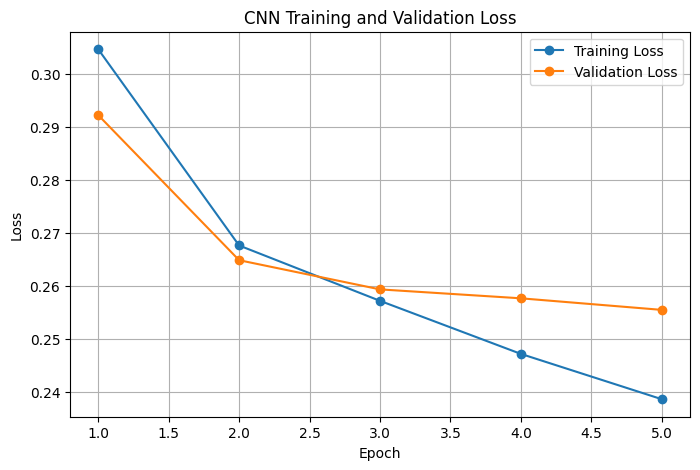

Loss curve saved.


In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, NUM_EPOCHS + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    "../results/cnn_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Loss curve saved.")

In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

model.eval()

all_predictions = []
all_labels = []
all_probabilities = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)

        outputs = model(X_batch).squeeze(1)

        probabilities = torch.sigmoid(outputs)
        predictions = (probabilities >= 0.5).float()

        all_probabilities.extend(probabilities.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(y_batch.numpy())

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions)
recall = recall_score(all_labels, all_predictions)
f1 = f1_score(all_labels, all_predictions)
cm = confusion_matrix(all_labels, all_predictions)

print("MODEL 1 - Test Set Performance")
print("--------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print("\nConfusion Matrix:")
print(cm)

MODEL 1 - Test Set Performance
--------------------------------
Accuracy:  0.9043
Precision: 0.9448
Recall:    0.8190
F1 Score:  0.8774

Confusion Matrix:
[[13017   464]
 [ 1755  7939]]


In [33]:
cnn_test_results = test_df.copy()

cnn_test_results["prediction"] = [
    int(x) for x in all_predictions
]

cnn_test_results["probability"] = [
    float(x) for x in all_probabilities
]

cnn_test_results.to_csv(
    "../results/cnn_test_original.csv",
    index=False
)

print("Test predictions saved.")
print(cnn_test_results.head())

Test predictions saved.
                        URL  label  prediction  probability
0                 motley.ie      1           0     0.019885
1         cryptocompare.com      1           1     0.690088
2        liuy-9a930.web.app      0           1     0.996743
3         fairytalesinc.com      0           0     0.072731
4  mechinchem-5cb8a.web.app      0           1     0.996911


In [34]:
import json

results_summary = {
    "model": "Character-level CNN",
    "dataset": "test_original",
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1": float(f1),
    "confusion_matrix": cm.tolist(),
    "label_mapping": {
        "original_label_0": "phishing",
        "original_label_1": "legitimate",
        "model_label_0": "legitimate",
        "model_label_1": "phishing"
    }
}

with open("../results/cnn_test_original.json", "w") as f:
    json.dump(results_summary, f, indent=4)

print("Test results JSON saved.")
print(json.dumps(results_summary, indent=4))

Test results JSON saved.
{
    "model": "Character-level CNN",
    "dataset": "test_original",
    "accuracy": 0.9042502696871629,
    "precision": 0.9447816256099012,
    "recall": 0.8189601815556014,
    "f1": 0.8773829916560756,
    "confusion_matrix": [
        [
            13017,
            464
        ],
        [
            1755,
            7939
        ]
    ],
    "label_mapping": {
        "original_label_0": "phishing",
        "original_label_1": "legitimate",
        "model_label_0": "legitimate",
        "model_label_1": "phishing"
    }
}


In [25]:
baseline_results = {
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1": f1
}

print(baseline_results)

{'accuracy': 0.9061488673139159, 'precision': 0.9601028025945417, 'recall': 0.8092634619352177, 'f1': 0.8782535684298909}


## Final Evaluation — Original Dataset Labels

In [1]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

In [13]:
# Load the saved CNN baseline

model = CharacterCNN(
    vocab_size=VOCAB_SIZE,
    embedding_dim=32
).to(device)

model.load_state_dict(
    torch.load(
        "../models/cnn_baseline.pt",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Saved CNN baseline loaded successfully.")

Saved CNN baseline loaded successfully.


In [17]:
test_df = pd.read_csv("../data/test.csv")

test_df["URL"] = test_df["URL"].apply(canonicalize_model_url)

print("Test set:", test_df.shape)
print(test_df["label"].value_counts())

Test set: (23175, 2)
label
1    13481
0     9694
Name: count, dtype: int64


In [18]:
def encode_url(url):
    encoded = []

    for char in url[:MAX_LEN]:
        if char in char_to_index:
            encoded.append(char_to_index[char])
        else:
            encoded.append(UNK_IDX)

    while len(encoded) < MAX_LEN:
        encoded.append(PAD_IDX)

    return encoded

In [19]:
from torch.utils.data import Dataset, DataLoader

class URLDataset(Dataset):
    def __init__(self, df):
        self.urls = df["URL"].tolist()
        self.labels = df["label"].tolist()

    def __len__(self):
        return len(self.urls)

    def __getitem__(self, index):
        encoded_url = encode_url(self.urls[index])

        # CNN's internal labels:
        # 0 = legitimate
        # 1 = phishing
        label = 1 if self.labels[index] == 0 else 0

        return (
            torch.tensor(encoded_url, dtype=torch.long),
            torch.tensor(label, dtype=torch.float32)
        )

In [20]:
test_dataset = URLDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False
)

print("Test batches:", len(test_loader))

Test batches: 91


In [21]:
all_probabilities = []

with torch.no_grad():
    for X_batch, _ in test_loader:
        X_batch = X_batch.to(device)

        logits = model(X_batch)
        probabilities = torch.sigmoid(logits).squeeze(1)

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

print("Predictions:", len(all_probabilities))

Predictions: 23175


In [22]:
original_labels = test_df["label"].to_numpy()

phishing_true = (original_labels == 0).astype(int)

phishing_probabilities = np.array(all_probabilities)

predicted_phishing = (
    phishing_probabilities >= 0.5
).astype(int)

print("True phishing:", phishing_true.sum())
print("Predicted phishing:", predicted_phishing.sum())

True phishing: 9694
Predicted phishing: 8403


In [23]:
accuracy = accuracy_score(
    phishing_true,
    predicted_phishing
)

precision = precision_score(
    phishing_true,
    predicted_phishing
)

recall = recall_score(
    phishing_true,
    predicted_phishing
)

f1 = f1_score(
    phishing_true,
    predicted_phishing
)

roc_auc = roc_auc_score(
    phishing_true,
    phishing_probabilities
)

pr_auc = average_precision_score(
    phishing_true,
    phishing_probabilities
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1:        {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")

Accuracy:  0.9043
Precision: 0.9448
Recall:    0.8190
F1:        0.8774
ROC-AUC:   0.9413
PR-AUC:    0.9459


In [25]:
cm = confusion_matrix(
    phishing_true,
    predicted_phishing
)

print(cm)

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

[[13017   464]
 [ 1755  7939]]
True Negatives: 13017
False Positives: 464
False Negatives: 1755
True Positives: 7939


In [26]:
cnn_metrics = {
    "model": "Character-level CNN",
    "dataset": "test",

    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1": float(f1),
    "roc_auc": float(roc_auc),
    "pr_auc": float(pr_auc),

    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp),

    "confusion_matrix": cm.tolist(),

    "label_mapping": {
        "dataset_label_0": "phishing",
        "dataset_label_1": "legitimate",
        "saved_prediction_0": "phishing",
        "saved_prediction_1": "legitimate",
        "model_internal_label_0": "legitimate",
        "model_internal_label_1": "phishing"
    }
}

with open(
    "../results/cnn_test_original.json",
    "w"
) as f:
    json.dump(cnn_metrics, f, indent=2)

print("Updated cnn_test_original.json successfully.")

Updated cnn_test_original.json successfully.
